<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQEmbedSVM_IntrusionDetection_Sciammarelli2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum embedding + SVM for intrusion detection (UNSW-NB15): Sciammarelli and Ahmed (2026) step by step

This notebook re-implements, runs and checks the method of

> Jessica A. Sciammarelli and Waqas Ahmed, "Quantum AI for Cybersecurity: A hybrid Quantum-Classical models for attack path analysis",
> arXiv:2601.02237 [cs.CR], January 2026. https://arxiv.org/abs/2601.02237

The paper publishes no code. Everything below is written from the description in its Section III, with the software stack it names:
PennyLane `default.qubit` for the circuit and scikit-learn for the classical models.

**What the notebook does.** It downloads the official UNSW-NB15 training and testing partitions (175,341 and 82,332 network flows),
keeps the paper's eight flow attributes (`dur, proto, service, state, spkts, dpkts, sbytes, dbytes`), label-encodes the three categorical
ones and Min-Max scales everything to [0, 1]. It then (1) trains Logistic Regression, a linear SVM and an RBF SVM on the full data
(paper Table II), (2) draws a 200-flow subset (160 training / 40 test) and trains the same classical models on it (Table III), and
(3) passes the 200 flows through an 8-qubit circuit (angle encoding `RY(x_i)`, 2 `StronglyEntanglingLayers`, `<Z_i>` read-out) and
classifies the resulting 8-dimensional "quantum embedding" with a classical SVM (Tables III-IV, Figs. 3-4). Because the paper
reports a single, unknown 200-flow draw and a 40-flow test set (one flow = 2.5 accuracy points), the small-sample experiment is repeated
over many independent draws, a diagnosis of why the quantum pipeline predicts "attack" for every flow is added, and the paper's
central hypothesis (quantum embeddings help when training data are scarce) is tested with a learning curve on the official test partition.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a pinned
PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and no Hugging Face
token are needed: the dataset mirror is public. (If you point `HF_REPO_MAIN` at a *gated* mirror, add your own token under
Colab *Settings -> Secrets* as `HF_TOKEN`; the notebook reads it from there and never prints it.)

**Runtime.** `FAST_MODE = True` (10 draws, short learning curve) takes a few minutes on a laptop CPU; `FAST_MODE = False`
(50 draws, learning curve up to 2,000 training flows, 20 random circuits) is the committed run. The timing of the committed run is printed in the last cell.

**What you get at the end.** The paper's Table II, III and IV re-computed with a verdict per claim, the paper's figures redrawn,
dataset and circuit diagrams, a repeated-draw study that shows how much the single 40-flow result can vary, and a short critical reading.


## The paper in one page

**Problem.** Binary intrusion detection (benign vs attack) on UNSW-NB15 network flows. The title and the contributions talk about
"attack path analysis", "attack graphs", "graph learning" and "quantum graph kernels", but Section III.B says that no graph is built:
each flow is merely *interpreted* as a small interaction graph and the eight flow attributes "approximate local graph behaviour".
The experiment is therefore a plain tabular flow classifier.

**Method (Algorithm 1, Fig. 1).** (1) feature-based "graph abstraction"; (2) label-encode `proto`, `service`, `state`, Min-Max scale to [0, 1];
(3) angle encoding `x_i -> RY(theta_i)` on 8 qubits, a variational circuit of 2 `StronglyEntanglingLayers`, read out the Pauli-Z expectation
values -> an 8-dimensional "quantum embedding"; (4) train a classical SVM on the embeddings. Everything runs on PennyLane's `default.qubit`.
The circuit has no trained parameters ("absence of trainable quantum parameters", Section IV.C).

**Data.** UNSW-NB15, "approximately 257,000" flows in the official split: 175,341 training and 82,332 testing. For the quantum model a
subset of 200 flows is split 80 / 20 (160 / 40). Classical baselines are trained on the full training partition (the RBF SVM on a subsample)
and, for the comparison, on the same 200-flow subset.

**Claims.**

| Where | Claim |
|---|---|
| Table II (full data) | Accuracy: Logistic Regression 68.8 %, Linear SVM 69.1 %, RBF SVM 68.9 % |
| Sec. IV.A | Attack recall about 97-98 %, benign recall only about 33-34 % for all three |
| Table III (200 flows) | Accuracy: Logistic Regression 72.5 %, Linear SVM 80.0 %, RBF SVM 80.0 %, **Quantum Embedding + SVM 64.0 %** |
| Table IV, Fig. 3-4 (200 flows) | Quantum + SVM: attack recall 1.00, benign recall 0.00, macro F1 0.39; the confusion matrix is `[[0, 72], [0, 128]]` (all 200 flows) |
| Abstract, Sec. IV.C | "superior attack recall and improved class separability when data is scarce"; quantum embeddings "capture complex correlations inaccessible to shallow classical models" |

Note that the supports of Table IV (72 + 128 = 200) and the confusion matrix of Fig. 4 add up to **200**, not to the 40 test flows
of the 80 / 20 split: the quantum numbers of Tables IV and Fig. 4 evidently cover all 200 flows, training flows included.
The notebook therefore reports both the 40 held-out flows and all 200 flows.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UNSW-NB15, 175,341 train / 82,332 test | same official partitions, public Hugging Face parquet mirror `research-simulation26/unsw-nb15-parquet` (fallback `Mireu-Lab/UNSW-NB15`) |
| Features | 8: `dur, proto, service, state, spkts, dpkts, sbytes, dbytes` | same |
| Categorical encoding | label encoding, encoders fitted jointly on train + test | same (category names only, never labels) |
| Scaling | Min-Max to [0, 1], fitted on? | `# CHOICE:` full-data models: fitted on the training partition, test clipped. Subset: both a *strict* version (fitted on the 160 subset-training flows) and a *global* version (fitted on the whole training partition, closest to the paper's global normalisation) are run |
| Qubits / encoding | 8 qubits, `RY(theta_i)`, `theta_i = x_i` | same, angle in radians = scaled feature (`ANGLE_SCALE = 1`) |
| Variational block | `StronglyEntanglingLayers`, 2 layers, no trained parameters | same; `# CHOICE:` 48 weights drawn uniformly in [0, 2 pi) from `WEIGHT_SEED` and frozen |
| Read-out | `<Z_i>` on every qubit | same |
| Classifier on the embedding | "classical SVM" | `# CHOICE:` `SVC(kernel="rbf", C=1, gamma="scale")` (scikit-learn defaults) |
| Classical baselines | LR, linear SVM, RBF SVM (subsampled) | `LogisticRegression`, `LinearSVC` (full data) / `SVC(linear)` (subset), `SVC(rbf)`; `# CHOICE:` all with default `C = 1`, RBF subsample `RBF_FULL_SUBSAMPLE` |
| 200-flow subset | 200 flows, 80 / 20 | `# CHOICE:` uniform random draw from the official training partition, stratified 160 / 40 split; repeated over `N_REPEATS` draws |
| Evaluation of the quantum model | Table IV on 200 flows | both: 40 held-out flows and all 200 flows |
| Simulator / hardware | `default.qubit`, no noise | same |
| Seeds | not given | `SEED = 42` everywhere |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, pyarrow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")


pennylane already present; skipping pip install.


### Configuration

Every tunable constant lives in the next cell. `FAST_MODE = True` keeps the repeated-draw studies and the learning curve small so the
whole notebook runs in a few minutes; `FAST_MODE = False` is the full study (committed outputs).

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo, a few minutes.  False: full budgets (more repeats, larger learning curve), about 15-25 minutes on a laptop CPU.
SEED      = 42              # master seed (data draws, circuit weights, scikit-learn random_state)

# Quantum embedding (paper Section III.D)
N_QUBITS  = 8               # paper: one qubit per feature, 8 features
N_LAYERS  = 2               # paper: StronglyEntanglingLayers, 2 layers
ANGLE_SCALE = 1.0           # CHOICE: the Min-Max scaled feature x in [0, 1] is used directly as the RY angle in radians (theta_i = x_i)
WEIGHT_SEED = SEED          # CHOICE: the paper has "no trainable quantum parameters", so the 48 circuit weights are random and FIXED;
                            #         the paper does not say how they were drawn -> uniform in [0, 2*pi) from this seed

# Small-sample experiment (paper Section III.F, Tables III-IV)
SUBSET_N    = 200           # paper: 200 flows
TEST_FRACTION = 0.20        # paper: 80 / 20 -> 160 training, 40 test flows
SUBSET_PARTITION = "train"  # CHOICE: the paper does not say where the 200 flows were drawn from; "train" or "test" partition of UNSW-NB15
N_REPEATS   = 10 if FAST_MODE else 50     # independent random draws of the 200-flow subset (the paper reports one unknown draw)
N_WEIGHT_SEEDS = 5 if FAST_MODE else 20   # random circuits compared in the circuit-sensitivity study

# Full-data classical baselines (Table II)
RBF_FULL_SUBSAMPLE = 3000 if FAST_MODE else 10000   # CHOICE: paper says RBF SVM was "subsampled", size not given

# Learning curve (extension, tests the paper's "quantum is better when data is scarce" hypothesis)
LC_SIZES = [50, 100, 200, 500] if FAST_MODE else [50, 100, 200, 500, 1000, 2000]
LC_SEEDS = 3 if FAST_MODE else 5
LC_TEST  = 2000 if FAST_MODE else 5000    # flows of the official testing partition used as a fixed evaluation set

# Data
DATA_DIR    = "unsw_nb15"   # downloaded files are cached here
LOCAL_TRAIN = ""            # optional: path to your own copy of the official training set (csv or parquet, 175,341 rows)
LOCAL_TEST  = ""            # optional: path to your own copy of the official testing set (82,332 rows)
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet, testing_set.parquet (public mirror)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback mirror: train.csv holds the official TESTING set, test.csv the TRAINING set
print("FAST_MODE =", FAST_MODE, "| repeats", N_REPEATS, "| learning-curve sizes", LC_SIZES)


FAST_MODE = False | repeats 50 | learning-curve sizes [50, 100, 200, 500, 1000, 2000]


In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, silhouette_score)

import pennylane as qml

# Hugging Face token: only needed for gated datasets; the UNSW-NB15 mirrors used here are public.
# In Colab, add HF_TOKEN under Settings > Secrets if you want to use a gated mirror of your own. It is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200)
NOTEBOOK_T0 = time.time()
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)


pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The UNSW-NB15 data

UNSW-NB15 (Moustafa and Slay, 2015) was produced by the Australian Centre for Cyber Security with the IXIA PerfectStorm tool: 49 features per
network flow and nine attack families (Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms) plus normal traffic.
The creators provide a partition into a training set of 175,341 flows and a testing set of 82,332 flows. That is the split the paper uses
("the standard UNSW-NB15 split") although it calls the total "approximately 257,000" (the original four CSV files hold 2.54 million flows;
the paper's Section I and Table I mix the two numbers). The parquet mirrors below contain the official partitions; the notebook caches them in `DATA_DIR`.

In [4]:
RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    # Common column names and labels across the two mirrors
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    df["label"] = df["label"].astype(int)
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    # Return (official training partition, official testing partition) as DataFrames
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)    # official training set
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)   # official testing set
        return tidy(read_any(a)), tidy(read_any(b))

t0 = time.time()
train_df, test_df = load_unsw()
assert len(train_df) > len(test_df), "partitions look swapped"
print(f"official UNSW-NB15 partitions: training {train_df.shape}, testing {test_df.shape} ({time.time() - t0:.0f} s)")
print("paper: 175,341 training and 82,332 testing flows ->", "matches" if (len(train_df), len(test_df)) == (175341, 82332) else "DIFFERENT")


loaded from research-simulation26/unsw-nb15-parquet


official UNSW-NB15 partitions: training (175341, 44), testing (82332, 44) (4 s)
paper: 175,341 training and 82,332 testing flows -> matches


## 2. Preprocessing: eight features, label encoding, Min-Max scaling

Paper Section III.C: keep eight attributes so that one feature maps to one qubit; label-encode the three text columns (`proto`, `service`, `state`);
scale everything to [0, 1] so that each value can serve directly as a rotation angle. Label encoding gives arbitrary integer codes, so the numeric
distance between two protocols carries no meaning; that is a weakness of the paper's design, not of this implementation.

Two things the paper does not specify are visible here. The byte and packet counts are heavy-tailed (a few flows carry megabytes while the typical flow carries hundreds of
bytes), so after Min-Max scaling most flows sit very close to 0, i.e. their `RY` angle is almost zero and the qubit stays almost in |0>. The printout of the "share of scaled
values below 0.05" quantifies this. And the paper does not say whether the scaler was fitted on all data or on the training part only; both are run for the 200-flow subset.

In [5]:
FEATURES = ["dur", "proto", "service", "state", "spkts", "dpkts", "sbytes", "dbytes"]   # paper Section III.C: the eight selected features
CATEGORICAL = ["proto", "service", "state"]
assert len(FEATURES) == N_QUBITS, "one feature per qubit"

# Label encoding of the three categorical columns. The paper fits the encoders JOINTLY on training and test data
# "to prevent unseen-category errors"; only the category names are used, never the labels.
vocab = {c: {v: i for i, v in enumerate(sorted(set(train_df[c]) | set(test_df[c])))} for c in CATEGORICAL}
print({c: len(v) for c, v in vocab.items()}, "categories per categorical feature (proto, service, state)")

def encode(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL:
        X[c] = X[c].map(vocab[c])
    return X.astype(float).to_numpy()

E_train, E_test = encode(train_df), encode(test_df)       # label-encoded, not yet scaled
y_train_full, y_test_full = train_df["label"].to_numpy(), test_df["label"].to_numpy()

# Min-Max scaling to [0, 1]. CHOICE: for the full-data models the scaler is fitted on the official TRAINING partition only
# and the test partition is clipped to [0, 1] (the paper does not say what the scaler was fitted on).
mm_full = MinMaxScaler().fit(E_train)
A_train_full = mm_full.transform(E_train)
A_test_full  = np.clip(mm_full.transform(E_test), 0.0, 1.0)
print("scaled training matrix", A_train_full.shape, "| test matrix", A_test_full.shape)
print("share of scaled values below 0.05 per feature (training partition):")
print(pd.Series((A_train_full < 0.05).mean(0), index=FEATURES).round(3).to_dict())


{'proto': 133, 'service': 13, 'state': 11} categories per categorical feature (proto, service, state)


scaled training matrix (175341, 8) | test matrix (82332, 8)
share of scaled values below 0.05 per feature (training partition):
{'dur': 0.949, 'proto': 0.021, 'service': 0.537, 'state': 0.075, 'spkts': 0.998, 'dpkts': 0.994, 'sbytes': 0.999, 'dbytes': 0.995}


### The 200-flow subset

Section III.F: "a reduced subset of 200 samples was extracted from the dataset and split into 80 percent training and 20 percent testing". The paper does not say how
the 200 flows were picked. Table IV (72 benign, 128 attack = 64 % attack) is consistent with a random draw from the training partition (68 % attack, so 64 % is within sampling noise)
and less so with the testing partition (55 % attack). We draw uniformly at random from the training partition, with a seed, and later repeat the draw many times.

In [6]:
# The 200-flow subset (paper Section III.F): 200 flows, split 80 / 20 into 160 training and 40 test flows.
# CHOICE: the paper does not say which 200 flows or how they were drawn; here a uniform random draw from one official partition.
SRC_E, SRC_Y, SRC_A = (E_train, y_train_full, A_train_full) if SUBSET_PARTITION == "train" else (E_test, y_test_full, A_test_full)

def draw_subset(seed):
    r = np.random.default_rng(seed)
    idx = r.choice(len(SRC_E), size=SUBSET_N, replace=False)
    tr_i, te_i = train_test_split(np.arange(SUBSET_N), test_size=TEST_FRACTION, stratify=SRC_Y[idx], random_state=seed)   # CHOICE: stratified
    return idx, idx[tr_i], idx[te_i]

def scale_subset(idx_tr, idx_te, mode):
    # mode "strict": Min-Max fitted on the 160 subset-training flows only, test clipped (project rule: no information from test flows).
    # mode "global": Min-Max fitted on the whole official training partition (the paper normalises the dataset globally, it seems).
    if mode == "global":
        return np.clip(mm_full.transform(SRC_E[idx_tr]), 0.0, 1.0), np.clip(mm_full.transform(SRC_E[idx_te]), 0.0, 1.0)
    sc = MinMaxScaler().fit(SRC_E[idx_tr])
    return sc.transform(SRC_E[idx_tr]), np.clip(sc.transform(SRC_E[idx_te]), 0.0, 1.0)

idx_all, idx_tr, idx_te = draw_subset(SEED)
Xs_tr, Xs_te = scale_subset(idx_tr, idx_te, "strict")
ys_tr, ys_te = SRC_Y[idx_tr], SRC_Y[idx_te]
print(f"subset drawn from the {SUBSET_PARTITION} partition with seed {SEED}: {len(idx_all)} flows -> {len(idx_tr)} training / {len(idx_te)} test")
print("attack share in the 200 flows: %.1f %% (paper: 128 / 200 = 64.0 %%)" % (100 * SRC_Y[idx_all].mean()))
print("training flows: benign %d, attack %d | test flows: benign %d, attack %d" % ((ys_tr == 0).sum(), (ys_tr == 1).sum(), (ys_te == 0).sum(), (ys_te == 1).sum()))


subset drawn from the train partition with seed 42: 200 flows -> 160 training / 40 test
attack share in the 200 flows: 73.0 % (paper: 128 / 200 = 64.0 %)
training flows: benign 43, attack 117 | test flows: benign 11, attack 29


## Dataset Exploration and Visualisation

The cells below show the real UNSW-NB15 flows that every later experiment uses: shape, column names, the original labels and their counts, the real class
distribution, and 2-D scatter plots of real flows coloured by their ground-truth label. The PCA is fitted on training flows only. The multiclass attack
category is kept (the paper works binary, but the families show that "attack" is a very heterogeneous class). Because the circuit uses angle encoding,
every scatter also appears with the coordinates scaled to [0, pi], the range an `RY` angle can use.

### Shape, feature names, labels and class counts

In [7]:
# --- shape, feature names, labels ---
print("training partition:", train_df.shape, "| testing partition:", test_df.shape)
print("all columns of the dataset (%d):" % train_df.shape[1], list(train_df.columns))
print("\nfeatures used by the paper (8):", FEATURES)
print("original binary label (0 = benign, 1 = attack) and attack category, training partition:")
display(pd.crosstab(train_df["attack_cat"], train_df["label"], margins=True))
print("testing partition:")
display(pd.crosstab(test_df["attack_cat"], test_df["label"], margins=True))
print("first rows of the eight features (raw, before encoding):")
display(train_df[FEATURES + ["label", "attack_cat"]].head())
display(train_df[FEATURES].describe().T[["min", "50%", "max"]].round(3))


training partition: (175341, 44) | testing partition: (82332, 44)
all columns of the dataset (44): ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

features used by the paper (8): ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes']
original binary label (0 = benign, 1 = attack) and attack category, training partition:


label,0,1,All
attack_cat,,,
Analysis,0,2000,2000
Backdoor,0,1746,1746
DoS,0,12264,12264
Exploits,0,33393,33393
Fuzzers,0,18184,18184
Generic,0,40000,40000
Normal,56000,0,56000
Reconnaissance,0,10491,10491
Shellcode,0,1133,1133


testing partition:


label,0,1,All
attack_cat,,,
Analysis,0,677,677
Backdoor,0,583,583
DoS,0,4089,4089
Exploits,0,11132,11132
Fuzzers,0,6062,6062
Generic,0,18871,18871
Normal,37000,0,37000
Reconnaissance,0,3496,3496
Shellcode,0,378,378


first rows of the eight features (raw, before encoding):


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,label,attack_cat
0,0.121478,tcp,-,FIN,6,4,258,172,0,Normal
1,0.649902,tcp,-,FIN,14,38,734,42014,0,Normal
2,1.623129,tcp,-,FIN,8,16,364,13186,0,Normal
3,1.681642,tcp,ftp,FIN,12,12,628,770,0,Normal
4,0.449454,tcp,-,FIN,10,6,534,268,0,Normal


,min,50%,max
dur,0.0,0.002,60.0
spkts,1.0,2.000,9616.0
dpkts,0.0,2.000,10974.0
sbytes,28.0,430.000,12965233.0
dbytes,0.0,164.000,14655550.0


### Class distributions

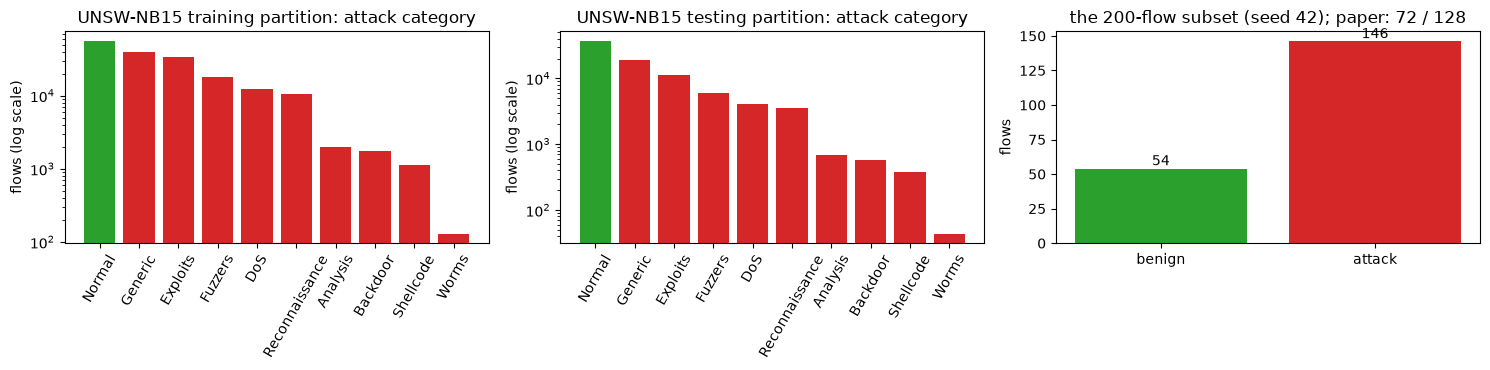

In [8]:
# --- class distributions (real counts) ---
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (nm, d) in zip(axs[:2], [("training partition", train_df), ("testing partition", test_df)]):
    vc = d["attack_cat"].value_counts()
    ax.bar(vc.index, vc.values, color=["tab:green" if k == "Normal" else "tab:red" for k in vc.index])
    ax.set_yscale("log"); ax.set_ylabel("flows (log scale)"); ax.set_title(f"UNSW-NB15 {nm}: attack category")
    ax.tick_params(axis="x", rotation=60)
sub_lab = SRC_Y[idx_all]
axs[2].bar(["benign", "attack"], [(sub_lab == 0).sum(), (sub_lab == 1).sum()], color=["tab:green", "tab:red"])
for i, v in enumerate([(sub_lab == 0).sum(), (sub_lab == 1).sum()]):
    axs[2].text(i, v, str(v), ha="center", va="bottom")
axs[2].set_title(f"the {SUBSET_N}-flow subset (seed {SEED}); paper: 72 / 128"); axs[2].set_ylabel("flows")
plt.tight_layout(); plt.show()


### Training flows in two dimensions (PCA fitted on the training partition)

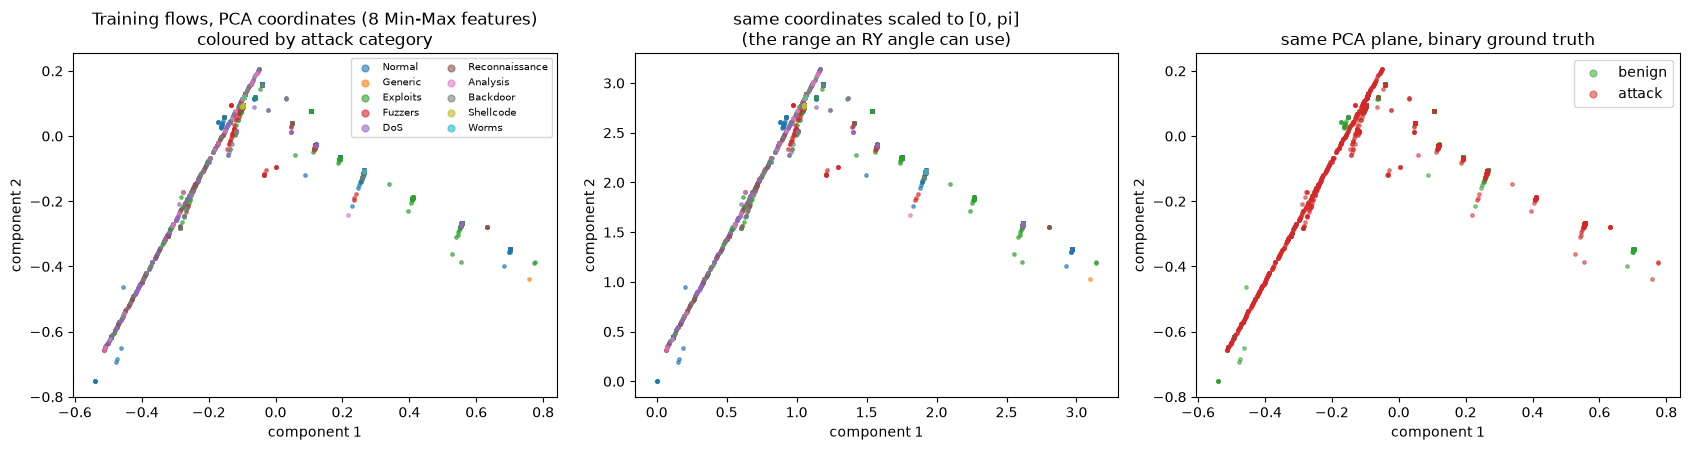

PCA of the 8 scaled features: explained variance of components 1-2 = 45.0 % / 29.4 %


In [9]:
# --- 2-D scatter of REAL flows coloured by ground truth: PCA fitted on the training split only ---
cats = list(train_df["attack_cat"].value_counts().index)
palette = dict(zip(cats, plt.cm.tab10(np.linspace(0, 1, 10))))
r_plot = np.random.default_rng(SEED)
plot_i = r_plot.choice(len(A_train_full), size=6000, replace=False)          # a random 6,000-flow sample of the training partition, for legibility
pca_full = PCA(n_components=2, random_state=SEED).fit(A_train_full)          # PCA of the Min-Max features, fitted on the training partition
P_plot = pca_full.transform(A_train_full[plot_i])
ang_full = MinMaxScaler((0.0, np.pi)).fit(pca_full.transform(A_train_full))
Pa_plot = np.clip(ang_full.transform(P_plot), 0.0, np.pi)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
for c in cats:
    m = train_df["attack_cat"].to_numpy()[plot_i] == c
    axs[0].scatter(P_plot[m, 0], P_plot[m, 1], s=6, alpha=0.6, color=palette[c], label=c)
    axs[1].scatter(Pa_plot[m, 0], Pa_plot[m, 1], s=6, alpha=0.6, color=palette[c])
axs[0].set_title("Training flows, PCA coordinates (8 Min-Max features)\ncoloured by attack category")
axs[1].set_title("same coordinates scaled to [0, pi]\n(the range an RY angle can use)")
yp = y_train_full[plot_i]
for lab, col, nm in [(0, "tab:green", "benign"), (1, "tab:red", "attack")]:
    axs[2].scatter(P_plot[yp == lab, 0], P_plot[yp == lab, 1], s=6, alpha=0.5, color=col, label=nm)
axs[2].set_title("same PCA plane, binary ground truth")
for a in axs[:2]: a.set_xlabel("component 1"); a.set_ylabel("component 2")
axs[2].set_xlabel("component 1"); axs[2].set_ylabel("component 2")
axs[0].legend(fontsize=7, markerscale=2, ncol=2); axs[2].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("PCA of the 8 scaled features: explained variance of components 1-2 = %.1f %% / %.1f %%" % tuple(100 * pca_full.explained_variance_ratio_))


### The 200-flow subset, and the angles the circuit actually receives

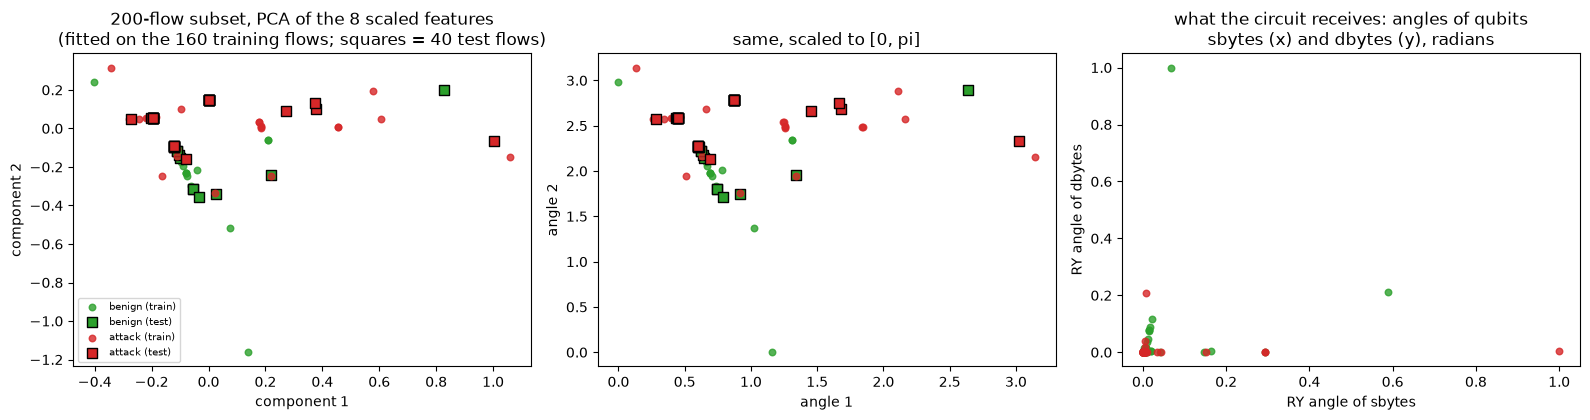

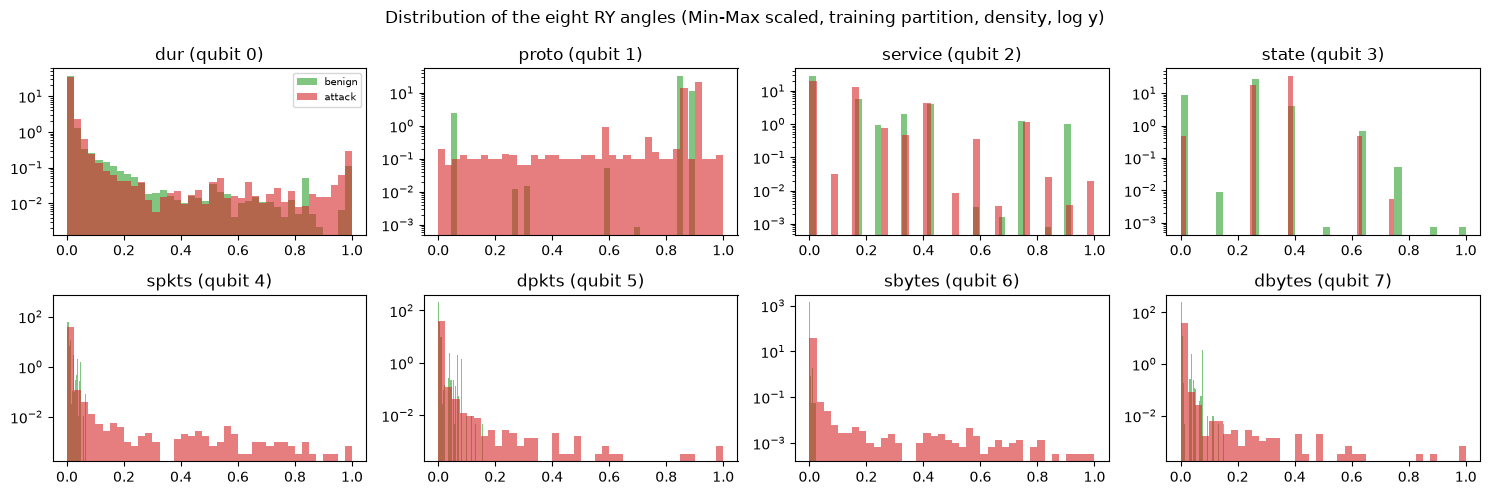

In [10]:
# --- the 200-flow subset itself: PCA fitted on its 160 training flows ---
pca_s = PCA(n_components=2, random_state=SEED).fit(Xs_tr)
Ps_tr, Ps_te = pca_s.transform(Xs_tr), pca_s.transform(Xs_te)
ang_s = MinMaxScaler((0.0, np.pi)).fit(Ps_tr)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for lab, col, nm in [(0, "tab:green", "benign"), (1, "tab:red", "attack")]:
    axs[0].scatter(Ps_tr[ys_tr == lab, 0], Ps_tr[ys_tr == lab, 1], s=22, color=col, alpha=0.8, label=f"{nm} (train)")
    axs[0].scatter(Ps_te[ys_te == lab, 0], Ps_te[ys_te == lab, 1], s=60, color=col, edgecolor="k", marker="s", label=f"{nm} (test)")
    axs[1].scatter(*np.clip(ang_s.transform(Ps_tr[ys_tr == lab]), 0, np.pi).T, s=22, color=col, alpha=0.8)
    axs[1].scatter(*np.clip(ang_s.transform(Ps_te[ys_te == lab]), 0, np.pi).T, s=60, color=col, edgecolor="k", marker="s")
# the raw (angle) coordinates the circuit actually sees: the first two encoded features that carry most variation
j1, j2 = FEATURES.index("sbytes"), FEATURES.index("dbytes")
for lab, col in [(0, "tab:green"), (1, "tab:red")]:
    axs[2].scatter(Xs_tr[ys_tr == lab, j1], Xs_tr[ys_tr == lab, j2], s=22, color=col, alpha=0.8)
axs[0].set_title("200-flow subset, PCA of the 8 scaled features\n(fitted on the 160 training flows; squares = 40 test flows)")
axs[1].set_title("same, scaled to [0, pi]")
axs[2].set_title("what the circuit receives: angles of qubits\nsbytes (x) and dbytes (y), radians")
axs[0].set_xlabel("component 1"); axs[0].set_ylabel("component 2"); axs[1].set_xlabel("angle 1"); axs[1].set_ylabel("angle 2")
axs[2].set_xlabel("RY angle of sbytes"); axs[2].set_ylabel("RY angle of dbytes"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

# histograms of the eight angles: the Min-Max scaling of heavy-tailed counts squeezes most flows near angle 0
fig, axs = plt.subplots(2, 4, figsize=(15, 5))
for j, (ax, f) in enumerate(zip(axs.ravel(), FEATURES)):
    ax.hist(A_train_full[y_train_full == 0, j], bins=40, alpha=0.6, color="tab:green", label="benign", density=True)
    ax.hist(A_train_full[y_train_full == 1, j], bins=40, alpha=0.6, color="tab:red", label="attack", density=True)
    ax.set_title(f"{f} (qubit {j})"); ax.set_yscale("log")
axs[0, 0].legend(fontsize=7); plt.suptitle("Distribution of the eight RY angles (Min-Max scaled, training partition, density, log y)")
plt.tight_layout(); plt.show()


## 3. Classical baselines on the full data (paper Table II, Fig. 2)

Logistic Regression, a linear SVM and an RBF-kernel SVM are trained on the official training partition (the RBF SVM on a random subsample, as in the paper,
whose size is not given) and evaluated on the official testing partition. Attack is the positive class. All inputs are the same eight Min-Max scaled features.

In [11]:
def clf_metrics(y, p, scores=None):
    out = dict(acc=100 * accuracy_score(y, p),
               prec=100 * precision_score(y, p, zero_division=0),
               rec_attack=100 * recall_score(y, p, zero_division=0),
               rec_benign=100 * recall_score(y, p, pos_label=0, zero_division=0),
               f1=100 * f1_score(y, p, zero_division=0),
               macro_f1=f1_score(y, p, average="macro", zero_division=0))
    if scores is not None and len(np.unique(y)) == 2:
        out["auc"] = roc_auc_score(y, scores)
    return out

t0 = time.time()
full_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Linear SVM":          LinearSVC(dual=False, C=1.0, random_state=SEED),          # CHOICE: C = 1 (paper: not stated)
}
full_pred, full_rows, full_time = {}, {}, {}
for name, model in full_models.items():
    t = time.time(); model.fit(A_train_full, y_train_full)
    p = model.predict(A_test_full); full_pred[name] = p
    full_rows[name] = clf_metrics(y_test_full, p, model.decision_function(A_test_full)); full_time[name] = time.time() - t
# RBF SVM on a random subsample of the training partition ("subsampled due to computational constraints")
sub_i = np.random.default_rng(SEED).choice(len(A_train_full), size=RBF_FULL_SUBSAMPLE, replace=False)
t = time.time(); rbf_full = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(A_train_full[sub_i], y_train_full[sub_i])
p = rbf_full.predict(A_test_full); full_pred["RBF SVM"] = p
full_rows["RBF SVM"] = clf_metrics(y_test_full, p, rbf_full.decision_function(A_test_full)); full_time["RBF SVM"] = time.time() - t
full_df = pd.DataFrame(full_rows).T.round(2)
full_df["time (s)"] = pd.Series(full_time).round(1)
print(f"Classical models, official training partition ({len(A_train_full):,} flows; RBF SVM on a {RBF_FULL_SUBSAMPLE:,}-flow subsample) -> official testing partition ({len(A_test_full):,} flows)")
display(full_df)


Classical models, official training partition (175,341 flows; RBF SVM on a 10,000-flow subsample) -> official testing partition (82,332 flows)


,acc,prec,rec_attack,rec_benign,f1,macro_f1,auc,time (s)
Logistic Regression,67.65,63.21,98.66,29.65,77.06,0.61,0.82,4.0
Linear SVM,69.48,64.50,99.17,33.12,78.16,0.64,0.83,3.4
RBF SVM,74.85,74.61,82.34,65.68,78.29,0.74,0.82,309.6


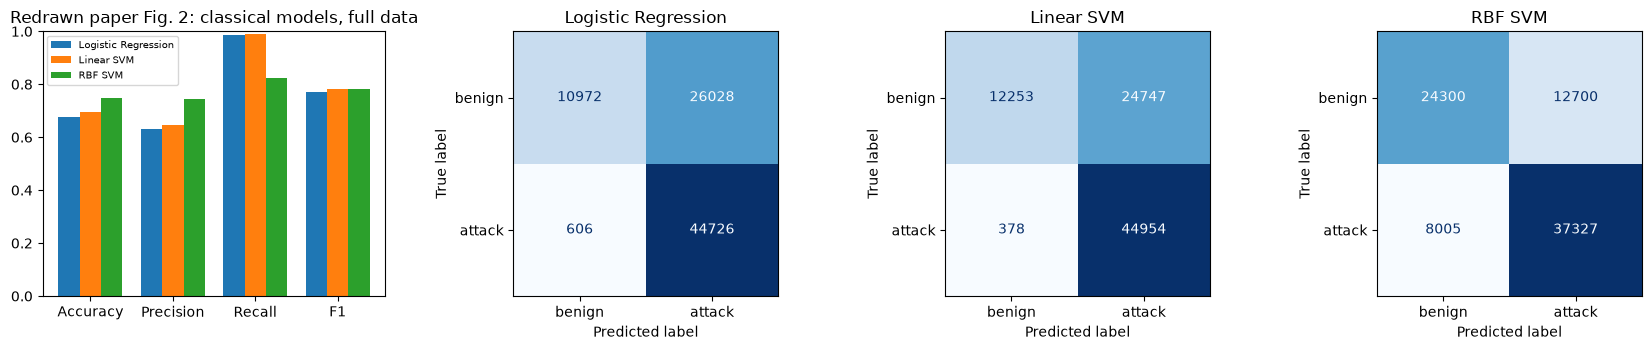

class balance of the testing partition: 55.1 % attack -> predicting 'attack' for everything would score 55.1 % accuracy


In [12]:
PAPER_TABLE2 = {"Logistic Regression": 68.8, "Linear SVM": 69.1, "RBF SVM": 68.9}
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
metric_names = ["acc", "prec", "rec_attack", "f1"]
x = np.arange(len(metric_names)); w = 0.26
for k, (name, row) in enumerate(full_rows.items()):
    axs[0].bar(x + (k - 1) * w, [row[m] / 100 for m in metric_names], w, label=name)
axs[0].set_xticks(x); axs[0].set_xticklabels(["Accuracy", "Precision", "Recall", "F1"]); axs[0].set_ylim(0, 1); axs[0].legend(fontsize=7)
axs[0].set_title("Redrawn paper Fig. 2: classical models, full data")
for a_, (name, p) in zip(axs[1:], full_pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test_full, p), display_labels=["benign", "attack"]).plot(ax=a_, cmap="Blues", colorbar=False)
    a_.set_title(name)
plt.tight_layout(); plt.show()
print("class balance of the testing partition: %.1f %% attack -> predicting 'attack' for everything would score %.1f %% accuracy" % (100 * y_test_full.mean(), 100 * y_test_full.mean()))


## Quantum Circuit Architecture

The paper's quantum part is one fixed circuit used as a feature transformation: eight qubits, one per feature; `RY(x_i)` angle encoding; two layers of PennyLane's
`StronglyEntanglingLayers` (per layer: a general rotation `Rot(phi, theta, omega)` on every qubit followed by a ring of CNOTs whose range grows with the layer index);
Pauli-Z expectation values on every qubit as the output. The drawings below are produced from the very QNode (`embedding_circuit`) that all experiments call.

Assumptions where the paper omits details: (i) the angle equals the Min-Max scaled feature in radians (no extra scaling); (ii) the 48 weights of the entangling layers are random,
frozen and uniform in [0, 2 pi) - the paper says only that there are no trainable quantum parameters; (iii) the default `StronglyEntanglingLayers` CNOT ranges (1, then 2) are used.

The QNode is defined first (it is needed to draw it), the figures and the resource count follow.

In [13]:
# The quantum embedding of paper Section III.D, written once and used everywhere below.
# Step 1  angle encoding: RY(x_i) on qubit i                         (PennyLane AngleEmbedding, rotation="Y")
# Step 2  variational block: StronglyEntanglingLayers, 2 layers      (Rot(phi, theta, omega) on every qubit + CNOT ring, per layer)
# Step 3  measurement: <Z_i> on every qubit  -> embedding q in [-1, 1]^8
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev)
def embedding_circuit(x, weights):
    qml.AngleEmbedding(ANGLE_SCALE * x, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

WEIGHT_SHAPE = qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS, n_wires=N_QUBITS)   # (2, 8, 3)
def init_weights(seed):
    # CHOICE: fixed random weights, uniform in [0, 2*pi) (the paper trains no quantum parameters and does not give the initialisation)
    return np.random.default_rng(seed).uniform(0.0, 2 * np.pi, WEIGHT_SHAPE)
W = init_weights(WEIGHT_SEED)

def embed(X, weights=None, chunk=2000):
    """Quantum embedding of every row of X (rows in [0,1]^8) -> array (n, 8) of <Z_i>. Uses PennyLane parameter broadcasting."""
    weights = W if weights is None else weights
    X = np.asarray(X, dtype=float)
    out = [np.stack([np.asarray(o) for o in embedding_circuit(X[i:i + chunk], weights)], axis=1) for i in range(0, len(X), chunk)]
    return np.concatenate(out, axis=0)

# sanity: the broadcast evaluation equals one-sample-at-a-time evaluation
x_demo = Xs_tr[:5]
one_by_one = np.array([[float(v) for v in embedding_circuit(x, W)] for x in x_demo])
assert np.allclose(embed(x_demo), one_by_one, atol=1e-10), "broadcasting changes the result"
print("broadcast embedding == single-sample embedding: OK | embedding shape for 5 flows:", embed(x_demo).shape)


broadcast embedding == single-sample embedding: OK | embedding shape for 5 flows: (5, 8)


### Drawings and resource count

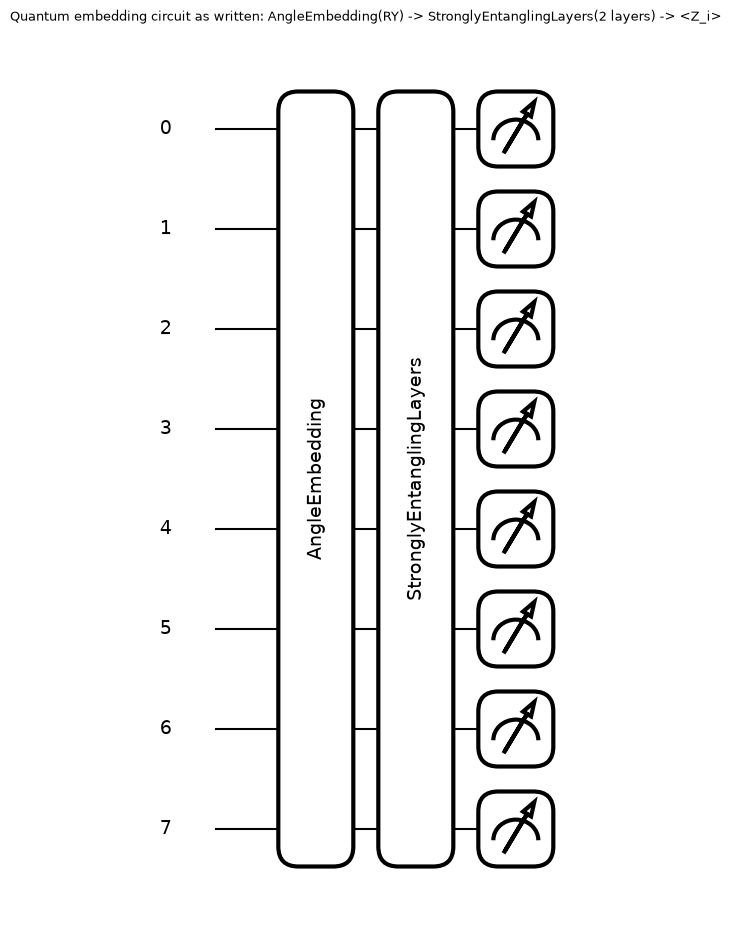

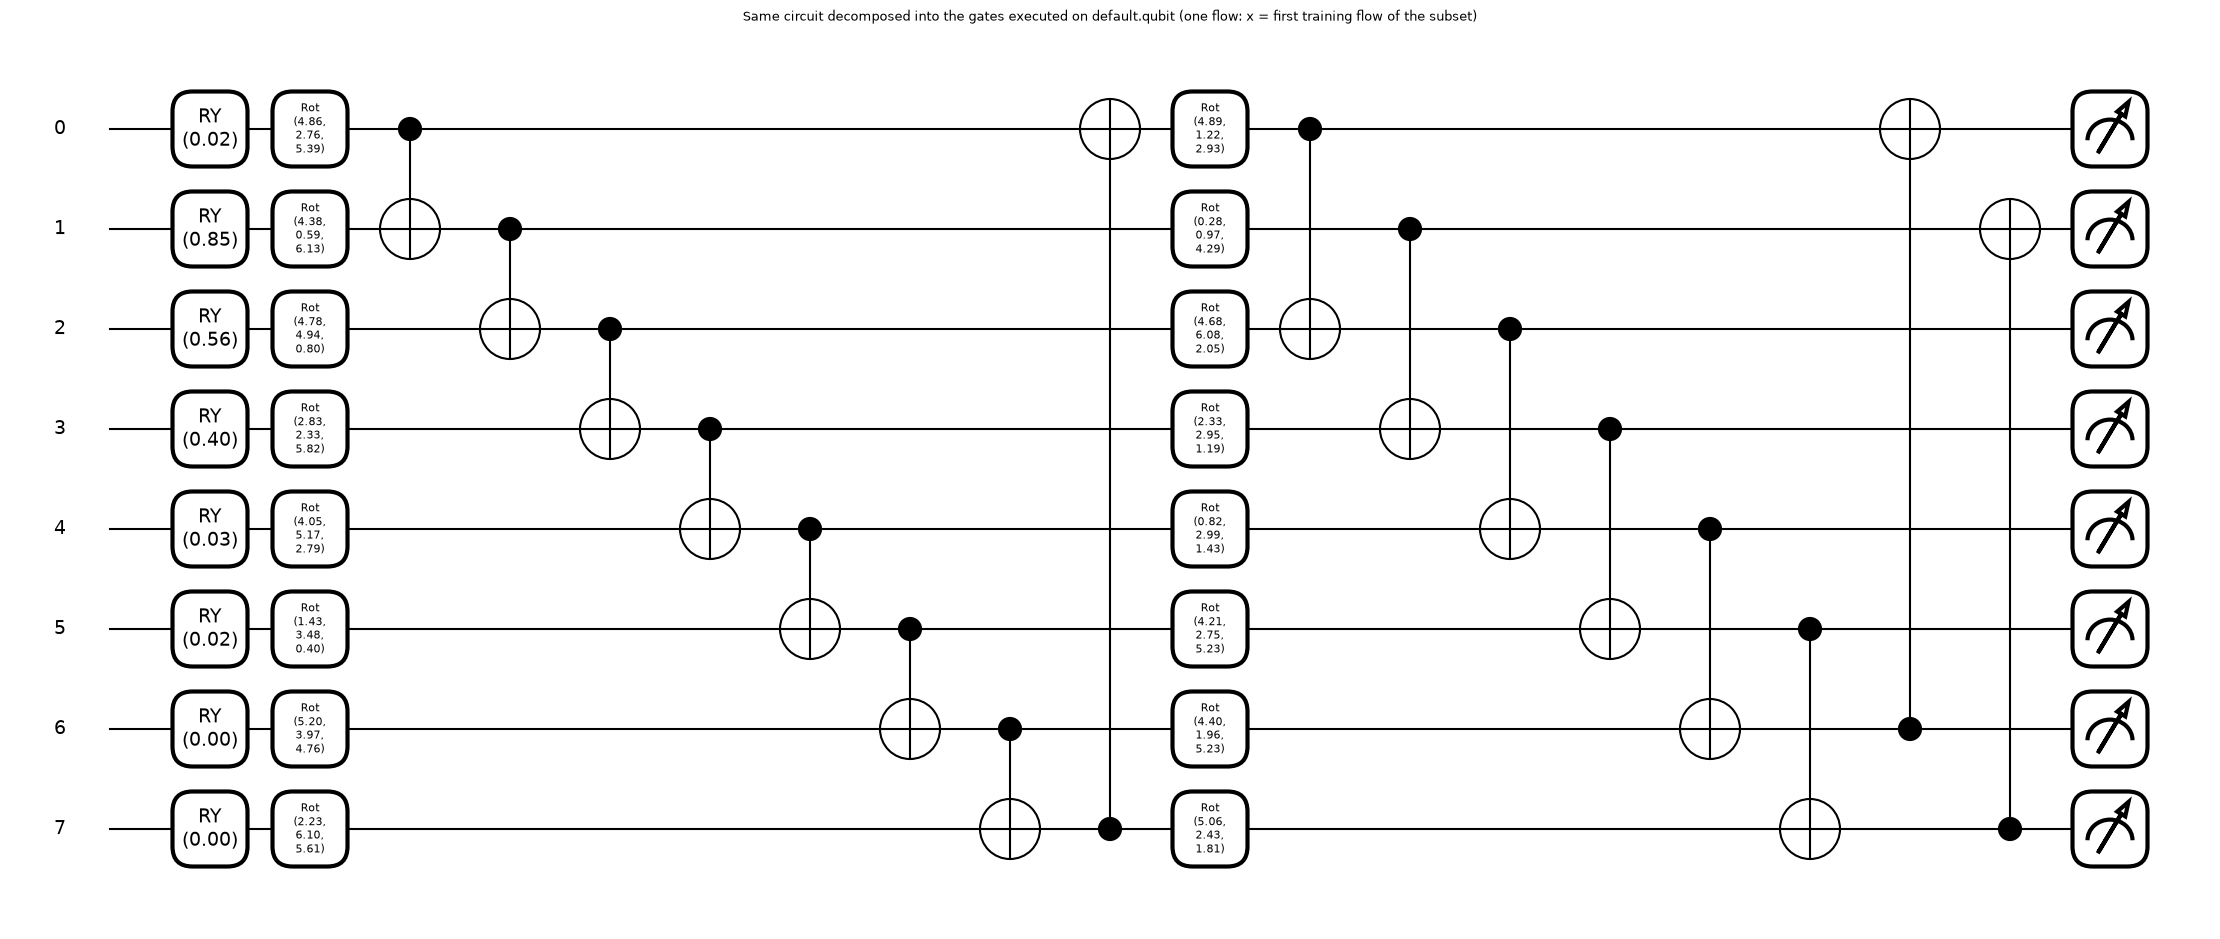

In [14]:
x0 = Xs_tr[0]
# (a) the circuit as written (templates as boxes) and (b) the gates actually executed on default.qubit
fig, ax = qml.draw_mpl(embedding_circuit, level="top", decimals=2)(x0, W)
ax.set_title("Quantum embedding circuit as written: AngleEmbedding(RY) -> StronglyEntanglingLayers(2 layers) -> <Z_i>", fontsize=9)
plt.show()
fig, ax = qml.draw_mpl(embedding_circuit, level="device", decimals=2)(x0, W)
ax.set_title("Same circuit decomposed into the gates executed on default.qubit (one flow: x = first training flow of the subset)", fontsize=9)
plt.show()


In [15]:
specs = qml.specs(embedding_circuit, level="device")(x0, W)
res = specs["resources"] if isinstance(specs, dict) else specs.resources
n_weights = int(np.prod(WEIGHT_SHAPE))
print("qubits                      :", N_QUBITS)
print("circuit depth (device level):", res.depth)
print("gate counts (device level)  :", dict(res.gate_types))
print("data-encoding parameters    :", N_QUBITS, "(one RY angle per feature, supplied by the flow)")
print("variational parameters      :", n_weights, "= %d layers x %d qubits x 3 Rot angles" % (N_LAYERS, N_QUBITS))
print("TRAINABLE parameters        : 0  (the paper trains nothing in the circuit: the %d weights stay at their random initial values)" % n_weights)
print("two-qubit gates (CNOT)      :", dict(res.gate_types).get("CNOT", 0))
print("measurements                : <Z_i> on all %d qubits -> embedding vector of length %d" % (N_QUBITS, N_QUBITS))
print("drawn circuit == executed circuit: the drawing above is produced from the same QNode object that embed() calls")


qubits                      : 8
circuit depth (device level): 15
gate counts (device level)  : {'RY': 8, 'Rot': 16, 'CNOT': 16}
data-encoding parameters    : 8 (one RY angle per feature, supplied by the flow)
variational parameters      : 48 = 2 layers x 8 qubits x 3 Rot angles
TRAINABLE parameters        : 0  (the paper trains nothing in the circuit: the 48 weights stay at their random initial values)
two-qubit gates (CNOT)      : 16
measurements                : <Z_i> on all 8 qubits -> embedding vector of length 8
drawn circuit == executed circuit: the drawing above is produced from the same QNode object that embed() calls


## 4. The 200-flow experiment: classical models vs "quantum embedding + SVM" (paper Tables III-IV, Figs. 3-4)

For one draw of the subset, the three classical models and the quantum pipeline are trained on the 160 training flows. The quantum pipeline is:
scaled features -> `embedding_circuit` -> 8 numbers in [-1, 1] -> `SVC`. Metrics are reported on the 40 held-out flows (the paper's protocol, Table III) and on all 200 flows
(what Table IV / Fig. 4 evidently show).

In [16]:
def make_models(seed):
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=seed),
        "Linear SVM":          SVC(kernel="linear", C=1.0, random_state=seed),
        "RBF SVM":             SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed),
    }

def run_draw(seed, mode="strict", weights=None, want_embeddings=False):
    """One draw of the 200-flow subset: train every model on the 160 training flows, evaluate on the 40 held-out flows
    and (as in the paper's Table IV / Fig. 4, whose supports add up to 200) also on all 200 flows."""
    idx, itr, ite = draw_subset(seed)
    Xa, Xb = scale_subset(itr, ite, mode)
    ya, yb = SRC_Y[itr], SRC_Y[ite]
    X200 = np.vstack([Xa, Xb]); y200 = np.concatenate([ya, yb])
    out = {}
    for name, m in make_models(seed).items():                               # classical models on the 8 scaled features
        m.fit(Xa, ya)
        out[name] = dict(test=clf_metrics(yb, m.predict(Xb), m.decision_function(Xb)),
                         all200=clf_metrics(y200, m.predict(X200)), pred_test=m.predict(Xb), pred_all=m.predict(X200))
    Qa, Qb = embed(Xa, weights), embed(Xb, weights)                         # quantum embeddings -> classical SVM
    q = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(Qa, ya)   # CHOICE: default scikit-learn SVC (the paper names no SVM settings)
    Q200 = np.vstack([Qa, Qb])
    out["Quantum Embedding + SVM"] = dict(test=clf_metrics(yb, q.predict(Qb), q.decision_function(Qb)),
                                          all200=clf_metrics(y200, q.predict(Q200)), pred_test=q.predict(Qb), pred_all=q.predict(Q200))
    out["_data"] = dict(Xa=Xa, Xb=Xb, ya=ya, yb=yb, y200=y200, Qa=Qa, Qb=Qb)
    return out

PAPER_TABLE3 = {"Logistic Regression": 72.5, "Linear SVM": 80.0, "RBF SVM": 80.0, "Quantum Embedding + SVM": 64.0}
t0 = time.time()
main_run = run_draw(SEED, "strict")
rows = []
for name in PAPER_TABLE3:
    r = main_run[name]
    rows.append(dict(model=name, **{"test-40 acc": r["test"]["acc"], "test-40 attack recall": r["test"]["rec_attack"], "test-40 benign recall": r["test"]["rec_benign"],
                                    "all-200 acc": r["all200"]["acc"], "all-200 attack recall": r["all200"]["rec_attack"], "all-200 benign recall": r["all200"]["rec_benign"],
                                    "all-200 macro F1": r["all200"]["macro_f1"], "paper acc (Table III)": PAPER_TABLE3[name]}))
main_df = pd.DataFrame(rows).set_index("model").round(2)
print(f"One draw (seed {SEED}), Min-Max fitted on the 160 training flows ({time.time() - t0:.1f} s)")
display(main_df)


One draw (seed 42), Min-Max fitted on the 160 training flows (0.8 s)


,test-40 acc,test-40 attack recall,test-40 benign recall,all-200 acc,all-200 attack recall,all-200 benign recall,all-200 macro F1,paper acc (Table III)
model,,,,,,,,
Logistic Regression,80.0,100.00,27.27,79.5,98.63,27.78,0.65,72.5
Linear SVM,85.0,100.00,45.45,83.0,98.63,40.74,0.73,80.0
RBF SVM,87.5,96.55,63.64,86.0,97.95,53.70,0.79,80.0
Quantum Embedding + SVM,75.0,96.55,18.18,77.5,97.26,24.07,0.61,64.0


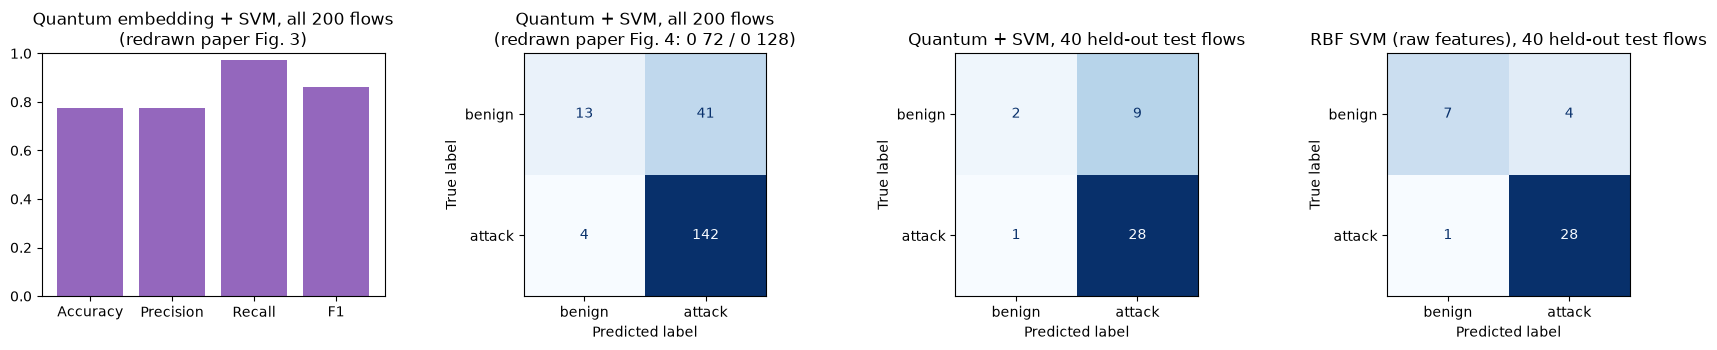

Classification report, quantum embedding + SVM, all 200 flows (paper Table IV format):
              precision    recall  f1-score   support

      Benign       0.76      0.24      0.37        54
      Attack       0.78      0.97      0.86       146

    accuracy                           0.78       200
   macro avg       0.77      0.61      0.61       200
weighted avg       0.77      0.78      0.73       200



In [17]:
# Redraw paper Fig. 3 (metrics) and Fig. 4 (confusion matrix) for the quantum embedding + SVM, and the classical models for contrast
q = main_run["Quantum Embedding + SVM"]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
mm = q["all200"]
axs[0].bar(["Accuracy", "Precision", "Recall", "F1"], [mm["acc"] / 100, mm["prec"] / 100, mm["rec_attack"] / 100, mm["f1"] / 100], color="tab:purple")
axs[0].set_ylim(0, 1); axs[0].set_title("Quantum embedding + SVM, all 200 flows\n(redrawn paper Fig. 3)")
y200 = main_run["_data"]["y200"]
ConfusionMatrixDisplay(confusion_matrix(y200, q["pred_all"], labels=[0, 1]), display_labels=["benign", "attack"]).plot(ax=axs[1], cmap="Blues", colorbar=False)
axs[1].set_title("Quantum + SVM, all 200 flows\n(redrawn paper Fig. 4: 0 72 / 0 128)")
ConfusionMatrixDisplay(confusion_matrix(main_run["_data"]["yb"], q["pred_test"], labels=[0, 1]), display_labels=["benign", "attack"]).plot(ax=axs[2], cmap="Blues", colorbar=False)
axs[2].set_title("Quantum + SVM, 40 held-out test flows")
ConfusionMatrixDisplay(confusion_matrix(main_run["_data"]["yb"], main_run["RBF SVM"]["pred_test"], labels=[0, 1]), display_labels=["benign", "attack"]).plot(ax=axs[3], cmap="Blues", colorbar=False)
axs[3].set_title("RBF SVM (raw features), 40 held-out test flows")
plt.tight_layout(); plt.show()
print("Classification report, quantum embedding + SVM, all 200 flows (paper Table IV format):")
print(classification_report(y200, q["pred_all"], target_names=["Benign", "Attack"], zero_division=0, digits=2))


### Repeating the draw: how much of the paper's number is luck?

With only 40 test flows the accuracy of any model moves in steps of 2.5 points and the benign class has about 13 test flows, so a single draw says little.
The experiment is repeated over independent draws of the 200 flows, once with the *strict* Min-Max fit (160 training flows only) and once with the *global* fit
(whole training partition, which is how the paper's normalisation reads). `single class` counts the draws where a model predicted one class for every flow.

In [18]:
# The paper reports ONE unknown draw of 200 flows, and a 40-flow test set moves accuracy in steps of 2.5 points.
# Here the whole experiment is repeated over N_REPEATS independent draws, with both Min-Max fitting modes.
t0 = time.time()
repeat_rows = []
for mode in ("strict", "global"):
    for s in range(N_REPEATS):
        run = run_draw(SEED + s, mode)
        for name in PAPER_TABLE3:
            r = run[name]
            repeat_rows.append(dict(mode=mode, seed=SEED + s, model=name, collapsed=bool(np.all(run[name]["pred_all"] == run[name]["pred_all"][0])),
                                    **{f"test_{k}": v for k, v in r["test"].items()}, **{f"all_{k}": v for k, v in r["all200"].items()}))
rep = pd.DataFrame(repeat_rows)
print(f"{N_REPEATS} draws x 2 scaling modes x 4 models in {time.time() - t0:.0f} s")
cols = ["test_acc", "test_rec_attack", "test_rec_benign", "test_auc", "all_acc", "all_rec_attack", "all_rec_benign", "all_macro_f1"]
summ = rep.groupby(["mode", "model"])[cols].agg(["mean", "std"]).round(2)
summ_ = rep.groupby(["mode", "model"])[["collapsed"]].mean().rename(columns={"collapsed": "share of draws predicting a single class"}).round(2)
for mode in ("strict", "global"):
    print(f"\n=== Min-Max fitted on the {'160 training flows' if mode == 'strict' else 'official training partition'} ({mode}) ===")
    display(summ.loc[mode].loc[list(PAPER_TABLE3)])
    display(summ_.loc[mode].loc[list(PAPER_TABLE3)])


50 draws x 2 scaling modes x 4 models in 83 s

=== Min-Max fitted on the 160 training flows (strict) ===


test_acc       test_rec_attack       test_rec_benign        test_auc       all_acc       all_rec_attack       all_rec_benign        all_macro_f1      
                            mean   std            mean   std            mean    std     mean   std    mean   std           mean   std           mean    std         mean   std
model                                                                                                                                                                         
Logistic Regression        76.95  4.32           97.69  3.97           29.38  16.26     0.85  0.06   78.16  3.13          98.26  1.55          32.37  11.22         0.66  0.06
Linear SVM                 78.90  5.35           97.74  4.19           35.48  19.92     0.85  0.06   80.13  3.83          98.27  1.83          38.73  15.07         0.70  0.08
RBF SVM                    80.05  4.91           95.82  4.83           43.50  17.58     0.88  0.05   82.24  3.12          97.23  3.11          47.67  13.51         0.75  0.06
Quantum Embedding + SVM    75.05  5.19           94.82  7.40           29.28  17.39     0.80  0.09   76.86  3.93          95.28  6.33          34.48  15.18         0.65  0.07

,share of draws predicting a single class
model,
Logistic Regression,0.00
Linear SVM,0.00
RBF SVM,0.00
Quantum Embedding + SVM,0.02



=== Min-Max fitted on the official training partition (global) ===


test_acc       test_rec_attack       test_rec_benign        test_auc       all_acc       all_rec_attack       all_rec_benign        all_macro_f1      
                            mean   std            mean   std            mean    std     mean   std    mean   std           mean   std           mean    std         mean   std
model                                                                                                                                                                         
Logistic Regression        73.00  2.90           99.57  1.19           11.83  12.94     0.80  0.07   73.33  2.47          99.60  0.61          13.05  11.77         0.52  0.09
Linear SVM                 73.90  3.36           99.42  1.53           15.30  13.36     0.84  0.07   74.41  2.87          99.48  0.64          17.16  11.52         0.56  0.09
RBF SVM                    75.45  3.67           99.00  1.94           21.85  11.66     0.86  0.05   76.38  2.86          99.14  0.80          24.94   6.12         0.62  0.04
Quantum Embedding + SVM    71.95  3.99           96.99  5.49           14.73  14.61     0.76  0.07   73.30  3.42          97.38  4.37          18.58  14.89         0.55  0.10

,share of draws predicting a single class
model,
Logistic Regression,0.30
Linear SVM,0.24
RBF SVM,0.00
Quantum Embedding + SVM,0.30


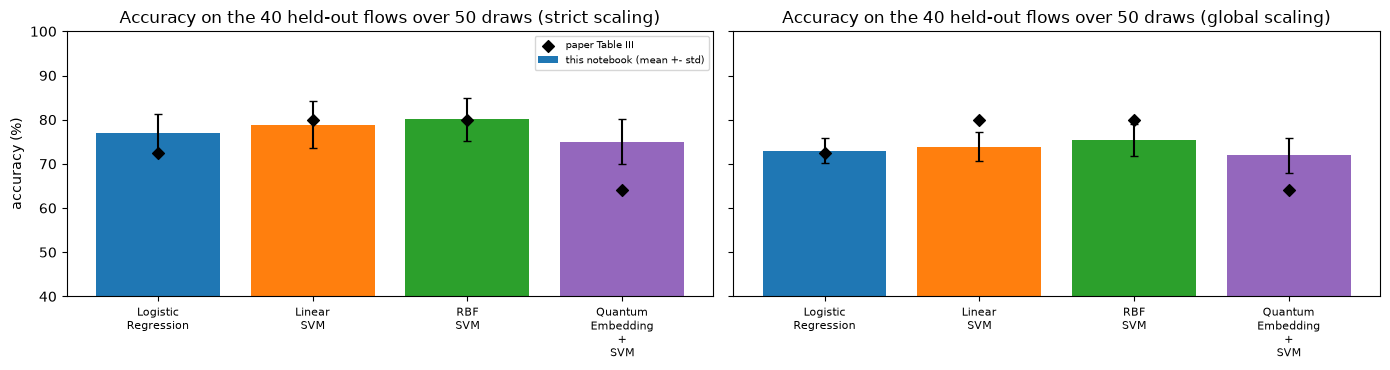

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, mode in zip(axs, ("strict", "global")):
    d = rep[rep["mode"] == mode]
    g = d.groupby("model")["test_acc"].agg(["mean", "std"]).loc[list(PAPER_TABLE3)]
    ax.bar(range(4), g["mean"], yerr=g["std"], capsize=3, color=["tab:blue", "tab:orange", "tab:green", "tab:purple"], label="this notebook (mean +- std)")
    ax.scatter(range(4), [PAPER_TABLE3[m] for m in g.index], color="k", zorder=3, marker="D", label="paper Table III")
    ax.set_xticks(range(4)); ax.set_xticklabels([m.replace(" ", "\n") for m in g.index], fontsize=8)
    ax.set_title(f"Accuracy on the 40 held-out flows over {N_REPEATS} draws ({mode} scaling)"); ax.set_ylim(40, 100)
axs[0].set_ylabel("accuracy (%)"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()


### Is the quantum embedding more separable than the raw features?

The paper concludes that the embeddings "strongly separate attack patterns" and have "improved class separability". Perfect attack recall obtained by labelling everything
as an attack is not separability. Two threshold-free measures are used instead: the silhouette coefficient of the true classes in each representation, and the 5-fold
cross-validated ROC AUC of an SVM trained on that representation (computed on the 160 training flows of every draw, so no test flow is involved).

In [20]:
# Is the quantum embedding more SEPARABLE than the raw features, as the paper argues? Three label-based, threshold-free measures,
# computed on the 160 training flows of every draw: silhouette of the true classes, and the cross-validated ROC AUC of a linear / RBF
# SVM trained on the representation (AUC does not depend on the decision threshold that makes the paper's classifier collapse).
from sklearn.model_selection import cross_val_predict
def sep_scores(Z, y, seed):
    sil = silhouette_score(Z, y)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    auc_rbf = roc_auc_score(y, cross_val_predict(SVC(kernel="rbf", gamma="scale"), Z, y, cv=cv, method="decision_function"))
    auc_lin = roc_auc_score(y, cross_val_predict(SVC(kernel="linear"), Z, y, cv=cv, method="decision_function"))
    return sil, auc_rbf, auc_lin

sep_rows = []
N_SEP = min(N_REPEATS, 20)
for mode in ("strict", "global"):
    for s in range(N_SEP):
        idx, itr, ite = draw_subset(SEED + s); Xa, _ = scale_subset(itr, ite, mode); ya = SRC_Y[itr]
        for rep_name, Z in (("raw 8 scaled features", Xa), ("quantum embedding (8 x <Z>)", embed(Xa))):
            sil, a1, a2 = sep_scores(Z, ya, SEED + s)
            sep_rows.append(dict(mode=mode, representation=rep_name, silhouette=sil, **{"5-fold AUC, RBF SVM": a1, "5-fold AUC, linear SVM": a2}))
sep = pd.DataFrame(sep_rows).groupby(["mode", "representation"]).agg(["mean", "std"]).round(3)
display(sep)


silhouette        5-fold AUC, RBF SVM        5-fold AUC, linear SVM       
                                         mean    std                mean    std                   mean    std
mode   representation                                                                                        
global quantum embedding (8 x <Z>)      0.145  0.057               0.780  0.031                  0.786  0.034
       raw 8 scaled features            0.128  0.039               0.827  0.031                  0.819  0.031
strict quantum embedding (8 x <Z>)      0.257  0.047               0.791  0.058                  0.794  0.047
       raw 8 scaled features            0.200  0.040               0.863  0.036                  0.839  0.036

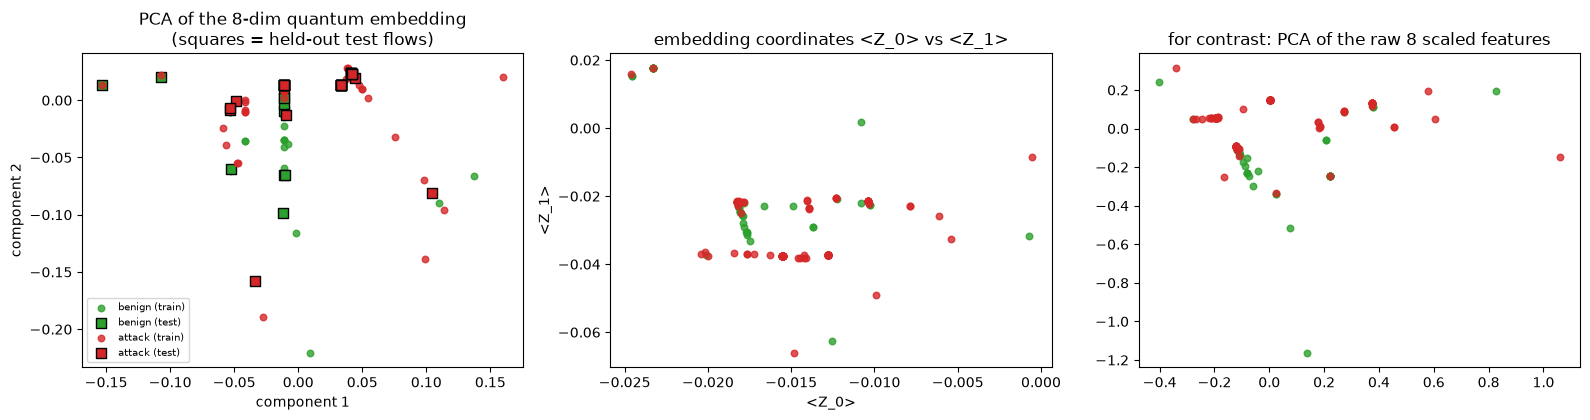

spread of each embedding coordinate (std over the 160 training flows): [0.004  0.0153 0.0129 0.0478 0.0053 0.035  0.0072 0.0251]
spread of each raw scaled feature (std):                               [0.1035 0.1272 0.2132 0.1741 0.1178 0.0867 0.1004 0.0831]


In [21]:
# Labelled 2-D view of the QUANTUM EMBEDDING space of the real 160 training + 40 test flows (PCA fitted on the training embeddings)
d = main_run["_data"]
pq = PCA(n_components=2, random_state=SEED).fit(d["Qa"])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for lab, col, nm in [(0, "tab:green", "benign"), (1, "tab:red", "attack")]:
    axs[0].scatter(*pq.transform(d["Qa"][d["ya"] == lab]).T, s=22, color=col, alpha=0.8, label=f"{nm} (train)")
    axs[0].scatter(*pq.transform(d["Qb"][d["yb"] == lab]).T, s=60, color=col, edgecolor="k", marker="s", label=f"{nm} (test)")
    axs[1].scatter(d["Qa"][d["ya"] == lab][:, 0], d["Qa"][d["ya"] == lab][:, 1], s=22, color=col, alpha=0.8)
    axs[2].scatter(*PCA(n_components=2, random_state=SEED).fit(d["Xa"]).transform(d["Xa"][d["ya"] == lab]).T, s=22, color=col, alpha=0.8)
axs[0].set_title("PCA of the 8-dim quantum embedding\n(squares = held-out test flows)"); axs[0].legend(fontsize=7)
axs[1].set_title("embedding coordinates <Z_0> vs <Z_1>"); axs[1].set_xlabel("<Z_0>"); axs[1].set_ylabel("<Z_1>")
axs[2].set_title("for contrast: PCA of the raw 8 scaled features"); axs[0].set_xlabel("component 1"); axs[0].set_ylabel("component 2")
plt.tight_layout(); plt.show()
print("spread of each embedding coordinate (std over the 160 training flows):", np.round(d["Qa"].std(0), 4))
print("spread of each raw scaled feature (std):                              ", np.round(d["Xa"].std(0), 4))


### Diagnosis: why does the pipeline predict "attack" for every flow?

Table IV's `[[0, 72], [0, 128]]` is the signature of a classifier that outputs the majority class. Two culprits are visible in the exploration section: (a) the Min-Max scaled
byte/packet angles are squeezed near 0, so every qubit is rotated by only a tiny angle and the 8 expectation values differ very little between flows (see the printed spread
of each embedding coordinate); (b) `SVC` with `gamma="scale"` and `C = 1` on such a narrow, imbalanced (64 % attack) cloud is easily dominated by the majority class.
The table below changes one thing at a time. These variants are **beyond the paper** and are only used to understand the result; none replaces the paper's pipeline in the verdicts.

In [22]:
# Why does the paper's quantum pipeline collapse to "everything is an attack"? Sensitivity of the SAME pipeline to choices the paper leaves open.
# These variants go BEYOND the paper (marked as such in the table below); they use the 160 training flows only for fitting and tuning.
def variants(seed, mode="strict"):
    idx, itr, ite = draw_subset(seed); Xa, Xb = scale_subset(itr, ite, mode); ya, yb = SRC_Y[itr], SRC_Y[ite]
    Qa, Qb = embed(Xa), embed(Xb)
    out = {}
    def add(name, model, A, B):
        model.fit(A, ya); p = model.predict(B); out[name] = (clf_metrics(yb, p, model.decision_function(B)), bool(np.all(p == p[0])))
    add("paper: SVC(rbf, C=1) on embedding", SVC(random_state=seed), Qa, Qb)
    sc = StandardScaler().fit(Qa)
    add("+ standardised embedding", SVC(random_state=seed), sc.transform(Qa), sc.transform(Qb))
    add("+ class_weight='balanced'", SVC(class_weight="balanced", random_state=seed), Qa, Qb)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    g0 = 1.0 / (Qa.shape[1] * Qa.var())   # the "scale" value of gamma
    grid = GridSearchCV(SVC(max_iter=200000, random_state=seed), {"C": [0.1, 1, 10, 100], "gamma": [g0 / 100, g0 / 10, g0]}, cv=cv).fit(Qa, ya)
    out["+ C, gamma tuned by 5-fold CV"] = (clf_metrics(yb, grid.predict(Qb), grid.decision_function(Qb)), bool(np.all(grid.predict(Qb) == grid.predict(Qb)[0])))
    add("classical: SVC(rbf, C=1) on raw", SVC(random_state=seed), Xa, Xb)
    g1 = 1.0 / (Xa.shape[1] * Xa.var())
    grid2 = GridSearchCV(SVC(max_iter=200000, random_state=seed), {"C": [0.1, 1, 10, 100], "gamma": [g1 / 100, g1 / 10, g1, 10 * g1]}, cv=cv).fit(Xa, ya)
    out["classical: C, gamma tuned by 5-fold CV"] = (clf_metrics(yb, grid2.predict(Xb), grid2.decision_function(Xb)), bool(np.all(grid2.predict(Xb) == grid2.predict(Xb)[0])))
    return out

N_VAR = min(N_REPEATS, 20)
var_rows = []
for s in range(N_VAR):
    for name, (m, coll) in variants(SEED + s).items():
        var_rows.append(dict(variant=name, seed=SEED + s, acc=m["acc"], rec_attack=m["rec_attack"], rec_benign=m["rec_benign"], auc=m["auc"], collapsed=coll))
var = pd.DataFrame(var_rows)
order = list(dict.fromkeys(var["variant"]))
var_tab = var.groupby("variant").agg(acc=("acc", "mean"), acc_std=("acc", "std"), rec_attack=("rec_attack", "mean"), rec_benign=("rec_benign", "mean"),
                                     auc=("auc", "mean"), single_class_share=("collapsed", "mean")).loc[order].round(2)
print(f"Mean over {N_VAR} draws (40 held-out flows each, strict scaling)")
display(var_tab)


Mean over 20 draws (40 held-out flows each, strict scaling)


,acc,acc_std,rec_attack,rec_benign,auc,single_class_share
variant,,,,,,
"paper: SVC(rbf, C=1) on embedding",75.38,5.27,95.64,28.06,0.80,0.05
+ standardised embedding,81.75,6.49,91.96,57.68,0.85,0.00
+ class_weight='balanced',75.12,6.46,72.53,81.33,0.83,0.00
"+ C, gamma tuned by 5-fold CV",80.88,6.24,93.30,51.54,0.84,0.00
"classical: SVC(rbf, C=1) on raw",81.12,5.53,94.24,50.20,0.89,0.00
"classical: C, gamma tuned by 5-fold CV",85.12,6.36,94.99,62.20,0.86,0.00


### Sensitivity to the random circuit

Because the 48 weights are random and untrained, the "quantum feature map" is one random draw from a family of circuits. The paper reports one of them.

20 random circuits x 10 draws: accuracy of 'embedding + SVC(rbf)' on 40 test flows
mean acc 75.6 +- 4.3 (across circuits) | mean benign recall 28.2 | share of runs predicting one class: 0.28


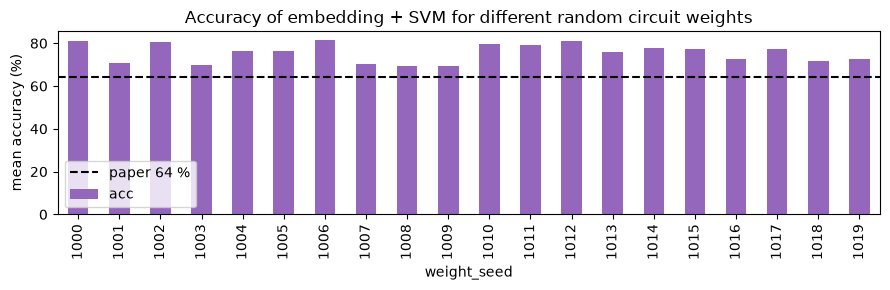

In [23]:
# Sensitivity to the random circuit: the paper fixes 48 random, untrained weights and does not say how. Different random circuits give different embeddings.
ws_rows = []
for ws in range(N_WEIGHT_SEEDS):
    w_ = init_weights(1000 + ws)
    for s in range(min(N_REPEATS, 10)):
        idx, itr, ite = draw_subset(SEED + s); Xa, Xb = scale_subset(itr, ite, "strict"); ya, yb = SRC_Y[itr], SRC_Y[ite]
        qa, qb = embed(Xa, w_), embed(Xb, w_)
        m = SVC(random_state=SEED).fit(qa, ya); p = m.predict(qb)
        ws_rows.append(dict(weight_seed=1000 + ws, draw=s, acc=100 * accuracy_score(yb, p), rec_attack=100 * recall_score(yb, p, zero_division=0),
                            rec_benign=100 * recall_score(yb, p, pos_label=0, zero_division=0), collapsed=bool(np.all(p == p[0]))))
wsd = pd.DataFrame(ws_rows)
per_w = wsd.groupby("weight_seed")[["acc", "rec_attack", "rec_benign", "collapsed"]].mean().round(2)
print(f"{N_WEIGHT_SEEDS} random circuits x {min(N_REPEATS, 10)} draws: accuracy of 'embedding + SVC(rbf)' on 40 test flows")
print("mean acc %.1f +- %.1f (across circuits) | mean benign recall %.1f | share of runs predicting one class: %.2f" %
      (per_w["acc"].mean(), per_w["acc"].std(), per_w["rec_benign"].mean(), wsd["collapsed"].mean()))
ax = per_w["acc"].plot.bar(figsize=(9, 3), color="tab:purple"); ax.axhline(64, color="k", ls="--", label="paper 64 %"); ax.set_ylabel("mean accuracy (%)")
ax.set_title("Accuracy of embedding + SVM for different random circuit weights"); ax.legend(); plt.tight_layout(); plt.show()


## 5. The paper's hypothesis: is the quantum embedding better when data is scarce? (learning curve)

The paper's research question is whether the hybrid model "can demonstrably outperform purely classical approaches ... especially when training data is limited". Its experiment compares one
200-flow draw only. Here the number of training flows is varied (50 to `max(LC_SIZES)`), each size repeated over `LC_SEEDS` draws, and every model is evaluated on the same fixed random
sample of the **official testing partition** (a much larger and distribution-shifted test set than 40 flows from the training partition). Logistic Regression and an RBF SVM on the raw
features are compared with the quantum embedding + SVM; the scaler is fitted on the training flows of each draw only.

learning curve in 381 s; evaluation set = 5000 flows of the official testing partition (55.2 % attack)


model,Logistic Regression (raw),Quantum Embedding + SVM,RBF SVM (raw)
n_train,,,
50,61.93,66.83,65.07
100,64.24,64.76,67.71
200,65.04,64.46,69.38
500,64.02,63.86,71.64
1000,64.92,63.34,71.80
2000,64.65,63.74,73.10


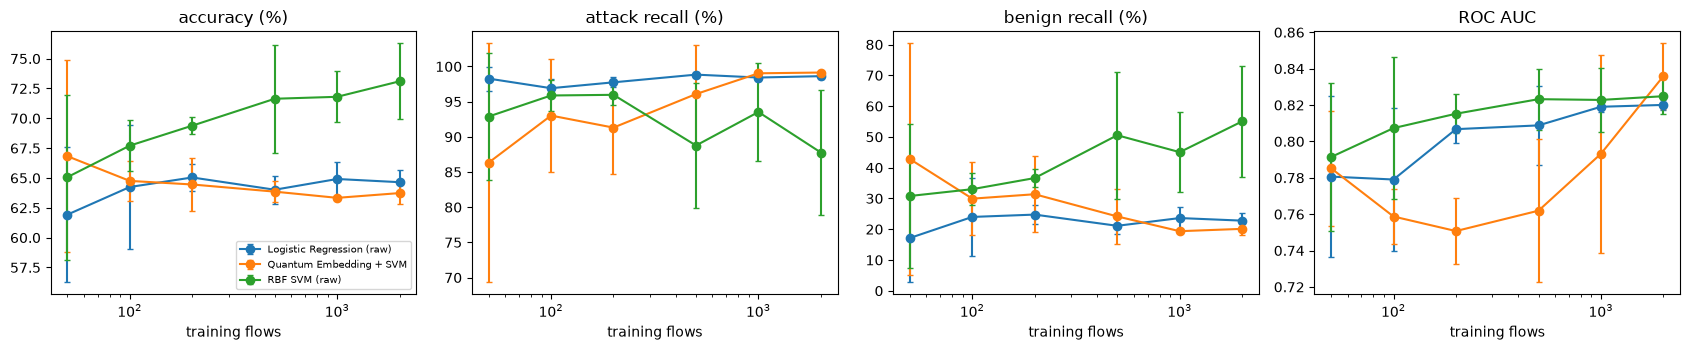

In [24]:
# Learning curve: is the quantum embedding better "when data is scarce"? Train on n flows drawn from the training partition
# (n = 50 ... ), evaluate on a fixed random sample of the OFFICIAL TEST partition; Min-Max fitted on the n training flows.
t0 = time.time()
lc_te_i = np.random.default_rng(SEED + 999).choice(len(E_test), size=LC_TEST, replace=False)
lc_E_te, lc_y_te = E_test[lc_te_i], y_test_full[lc_te_i]
lc_rows = []
for n in LC_SIZES:
    for s in range(LC_SEEDS):
        r = np.random.default_rng(SEED + 100 * s + n)
        i = r.choice(len(E_train), size=n, replace=False); ya = y_train_full[i]
        if len(np.unique(ya)) < 2: continue
        sc = MinMaxScaler().fit(E_train[i]); Xa = sc.transform(E_train[i]); Xb = np.clip(sc.transform(lc_E_te), 0, 1)
        Qa, Qb = embed(Xa), embed(Xb)
        for name, model, A, B in [("Logistic Regression (raw)", LogisticRegression(max_iter=2000), Xa, Xb),
                                  ("RBF SVM (raw)", SVC(random_state=SEED), Xa, Xb),
                                  ("Quantum Embedding + SVM", SVC(random_state=SEED), Qa, Qb)]:
            model.fit(A, ya); p = model.predict(B); m = clf_metrics(lc_y_te, p, model.decision_function(B))
            lc_rows.append(dict(n_train=n, seed=s, model=name, **m))
lc = pd.DataFrame(lc_rows)
lc_tab = lc.groupby(["model", "n_train"])[["acc", "rec_attack", "rec_benign", "auc"]].mean().round(2)
print(f"learning curve in {time.time() - t0:.0f} s; evaluation set = {LC_TEST} flows of the official testing partition ({100 * lc_y_te.mean():.1f} % attack)")
display(lc_tab.unstack(0)["acc"])
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (m_, ttl) in zip(axs, [("acc", "accuracy (%)"), ("rec_attack", "attack recall (%)"), ("rec_benign", "benign recall (%)"), ("auc", "ROC AUC")]):
    for name, g in lc.groupby("model"):
        gg = g.groupby("n_train")[m_].agg(["mean", "std"]); ax.errorbar(gg.index, gg["mean"], yerr=gg["std"], marker="o", capsize=2, label=name)
    ax.set_xscale("log"); ax.set_xlabel("training flows"); ax.set_title(ttl)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()


## 6. Side by side with the paper

Verdicts follow the project rule: **reproduced** when within 2 accuracy points (0.02 for F1), otherwise **not reached** / **exceeded** with the gap, **cannot be checked** when the notebook cannot test the claim.
Single-draw rows compare with the paper's single (unknown) draw; "mean of N draws" rows compare with the average over independent draws.

In [25]:
def v_tol(ours, paper, tol):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

mean_acc = lambda mode, model, col="test_acc": rep[(rep["mode"] == mode) & (rep["model"] == model)][col].mean()
full = full_rows
claims = []
# --- Table II (full data) ---
for m, pv in PAPER_TABLE2.items():
    claims.append(("Table II accuracy, " + m, f"{pv:.1f} %", f"{full[m]['acc']:.1f} %", v_tol(full[m]["acc"], pv, 2.0)))
for m in full:
    ra, rb = full[m]["rec_attack"], full[m]["rec_benign"]
    ok = abs(ra - 97.5) <= 2.5 and abs(rb - 33.5) <= 2.5
    claims.append((f"Sec. IV.A attack / benign recall, {m} (97-98 % / 33-34 %)", "97-98 % / 33-34 %", f"{ra:.1f} % / {rb:.1f} %",
                   "reproduced" if ok else f"not reached (attack {ra - 97.5:+.1f}, benign {rb - 33.5:+.1f} points)"))
# --- Table III (200 flows) ---
for m in ("Logistic Regression", "Linear SVM", "RBF SVM"):
    claims.append((f"Table III accuracy, {m} (single draw, seed {SEED}, 40 test flows)", f"{PAPER_TABLE3[m]:.1f} %",
                   f"{main_run[m]['test']['acc']:.1f} %", v_tol(main_run[m]["test"]["acc"], PAPER_TABLE3[m], 2.0)))
    claims.append((f"Table III accuracy, {m} (mean of {N_REPEATS} draws, global scaling)", f"{PAPER_TABLE3[m]:.1f} %",
                   f"{mean_acc('global', m):.1f} %", v_tol(mean_acc('global', m), PAPER_TABLE3[m], 2.0)))
qn = "Quantum Embedding + SVM"
claims.append((f"Table III accuracy, quantum + SVM (single draw, 40 test flows)", "64.0 %", f"{main_run[qn]['test']['acc']:.1f} %", v_tol(main_run[qn]["test"]["acc"], 64.0, 2.0)))
claims.append((f"Table III accuracy, quantum + SVM (mean of {N_REPEATS} draws, strict / global scaling)", "64.0 %",
               f"{mean_acc('strict', qn):.1f} % / {mean_acc('global', qn):.1f} %", v_tol(mean_acc('global', qn), 64.0, 2.0) + " (global)"))
# --- Table IV (quantum, 200 flows) ---
a200 = main_run[qn]["all200"]
claims.append(("Table IV attack recall = 1.00 (all 200 flows, single draw)", "100 %", f"{a200['rec_attack']:.1f} %", v_tol(a200["rec_attack"], 100.0, 2.0)))
claims.append(("Table IV benign recall = 0.00 (all 200 flows, single draw)", "0 %", f"{a200['rec_benign']:.1f} %", v_tol(a200["rec_benign"], 0.0, 2.0)))
claims.append(("Table IV macro F1 = 0.39 (all 200 flows, single draw)", "0.39", f"{a200['macro_f1']:.2f}", "reproduced" if abs(a200['macro_f1'] - 0.39) <= 0.02 else "not reached (%+.2f)" % (a200['macro_f1'] - 0.39)))
coll = rep[(rep["model"] == qn)].groupby("mode")["collapsed"].mean()
claims.append(("Table IV pattern: quantum + SVM predicts 'attack' for every flow (share of draws strict / global)", "all flows", f"{coll['strict']:.2f} / {coll['global']:.2f}",
               "reproduced" if coll["global"] >= 0.5 or coll["strict"] >= 0.5 else "not reached here"))
# --- qualitative claims ---
q_rec = rep[(rep["model"] == qn) & (rep["mode"] == "global")]["test_rec_attack"].mean(); c_rec = rep[(rep["model"] == "RBF SVM") & (rep["mode"] == "global")]["test_rec_attack"].mean()
claims.append(("Sec. IV.C 'superior attack recall when data is scarce' (quantum vs RBF SVM, mean attack recall, 40 test flows, global scaling)", "quantum higher", f"{q_rec:.1f} % vs {c_rec:.1f} %",
               ("reproduced as a number, but caused by predicting 'attack' for everything (benign recall %.1f %%)" % rep[(rep['model'] == qn) & (rep['mode'] == 'global')]['test_rec_benign'].mean()) if q_rec > c_rec else "not reached here"))
sep_g = sep.loc["global"]
claims.append(("Abstract 'improved class separability' (5-fold AUC of an RBF SVM, embedding vs raw, global scaling)", "embedding better",
               f"{sep_g.loc['quantum embedding (8 x <Z>)', ('5-fold AUC, RBF SVM', 'mean')]:.3f} vs {sep_g.loc['raw 8 scaled features', ('5-fold AUC, RBF SVM', 'mean')]:.3f}",
               "reproduced" if sep_g.loc['quantum embedding (8 x <Z>)', ('5-fold AUC, RBF SVM', 'mean')] > sep_g.loc['raw 8 scaled features', ('5-fold AUC, RBF SVM', 'mean')] + 0.01 else "not reached here"))
lc_small = lc[lc["n_train"] <= 200].groupby("model")["acc"].mean()   # the paper's scarce-data regime: 200 flows or fewer
claims.append(("Abstract 'better generalisation when data is scarce' (learning curve, mean accuracy for n <= 200 training flows, official test partition)", "quantum better",
               f"quantum {lc_small['Quantum Embedding + SVM']:.1f} % vs RBF {lc_small['RBF SVM (raw)']:.1f} % vs LR {lc_small['Logistic Regression (raw)']:.1f} %",
               "reproduced" if lc_small['Quantum Embedding + SVM'] > max(lc_small['RBF SVM (raw)'], lc_small['Logistic Regression (raw)']) + 2 else "not reached here"))
claims.append(("Graph / attack-path analysis (title, contributions: quantum graph kernels, graph classification)", "claimed", "no graph is built", "cannot be checked (paper itself uses a feature-based abstraction only)"))
cmp_df = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 140)
display(cmp_df)
print(cmp_df["verdict"].str.split(" ").str[0].value_counts().to_dict())
print("total notebook wall-clock: %.1f min" % ((time.time() - NOTEBOOK_T0) / 60))


,claim,paper,this notebook,verdict
0,"Table II accuracy, Logistic Regression",68.8 %,67.7 %,reproduced
1,"Table II accuracy, Linear SVM",69.1 %,69.5 %,reproduced
2,"Table II accuracy, RBF SVM",68.9 %,74.9 %,exceeded (+6.0)
3,"Sec. IV.A attack / benign recall, Logistic Regression (97-98 % / 33-34 %)",97-98 % / 33-34 %,98.7 % / 29.7 %,"not reached (attack +1.2, benign -3.8 points)"
4,"Sec. IV.A attack / benign recall, Linear SVM (97-98 % / 33-34 %)",97-98 % / 33-34 %,99.2 % / 33.1 %,reproduced
5,"Sec. IV.A attack / benign recall, RBF SVM (97-98 % / 33-34 %)",97-98 % / 33-34 %,82.3 % / 65.7 %,"not reached (attack -15.2, benign +32.2 points)"
6,"Table III accuracy, Logistic Regression (single draw, seed 42, 40 test flows)",72.5 %,80.0 %,exceeded (+7.5)
7,"Table III accuracy, Logistic Regression (mean of 50 draws, global scaling)",72.5 %,73.0 %,reproduced
8,"Table III accuracy, Linear SVM (single draw, seed 42, 40 test flows)",80.0 %,85.0 %,exceeded (+5.0)
9,"Table III accuracy, Linear SVM (mean of 50 draws, global scaling)",80.0 %,73.9 %,not reached (-6.1)


{'not': 10, 'exceeded': 7, 'reproduced': 4, 'cannot': 1}
total notebook wall-clock: 16.5 min


## 7. Reading the paper critically

The numbers below are those of the committed run (`FAST_MODE = False`, 50 draws of the 200-flow subset, 20 random circuits, learning curve up to 2,000 flows).

**What reproduced.** The data and the classical full-data baselines behave as the paper says: Logistic Regression and the linear SVM reach 67.7 % and 69.5 % accuracy on the official testing partition (paper 68.8 % and 69.1 %), with attack recall of 98.7-99.2 % and benign recall of 30-33 % (paper 97-98 % and 33-34 %). The reason is visible in the exploration section: the eight Min-Max scaled features separate the two classes only weakly (AUC about 0.82), and the testing partition holds 55 % attack flows, so a model that labels almost everything "attack" already scores about 55 %. The RBF SVM does not reproduce: trained on a 10,000-flow subsample it reaches 74.9 % (benign recall 66 %), because a non-linear boundary does help on this representation; the paper's 68.9 % with 97-98 % attack recall looks like an RBF SVM that behaved like a linear one (a very small or very large `gamma` or `C`, which the paper does not give).

**What did not reproduce.** (1) *The quantum result.* The paper's quantum embedding + SVM predicts "attack" for all 200 flows (accuracy 64 %, benign recall 0, macro F1 0.39). Here the same pipeline (random frozen 2-layer StronglyEntanglingLayers circuit, SVC with defaults) scores 75 % on 40 held-out flows with 29 % benign recall and predicts a single class in only 2 % of the draws with a per-subset Min-Max fit and in 30 % of the draws when the scaler is fitted on the whole training partition. Collapse to one class is therefore a real failure mode of this pipeline, but not the typical outcome; the paper's 64 % is an unlucky draw, a different SVM setting or both. (2) *The classical small-sample numbers.* Over 50 draws the three classical models score 73.0 % (LR), 73.9 % (linear SVM) and 75.5 % (RBF SVM) with the global scaler, against 72.5 %, 80.0 %, 80.0 % in the paper; the paper's single 40-flow test set moves accuracy in 2.5-point steps with a standard deviation of 3-5 points, so Table III cannot support the ordering it implies. (3) *"Perfect attack recall" as evidence of quantum sensitivity.* A recall of 1.00 with a benign recall of 0 is what a constant classifier gives; the notebook shows that the quantum model's attack recall (97.0 %) is not higher than the RBF SVM's (99.0 %) once many draws are averaged. (4) *"Improved class separability".* The 5-fold cross-validated AUC of an SVM on the quantum embedding (0.78) is lower than on the raw features (0.83); the silhouette of the true classes is slightly higher in the embedding space, but the scale of the embedding is tiny (coordinate standard deviations 0.004-0.05) so the silhouette says little. (5) *"Better generalisation when data is scarce".* In the learning curve on 5,000 official test flows, the quantum embedding is not better than the RBF SVM on raw features for 100, 200, 500, 1,000 or 2,000 training flows, and only ahead at 50 flows (66.8 % vs 65.1 %, within noise); the classical RBF SVM improves steadily with more data (73.1 % at 2,000 flows) while the embedding stays at about 64 %.

**Why the embedding is weak (diagnosis in Sections 4-5).** Min-Max scaling of heavy-tailed counts puts 95-99.9 % of the flows below 0.05 for `dur, spkts, dpkts, sbytes, dbytes`, so five of the eight `RY` rotations are almost the identity and the circuit sees nearly the same input for most flows. The random frozen entangling layers then scramble the few informative coordinates (the AUC falls from 0.83 to 0.78) and the expectation values vary by only a few percent between flows, which makes `SVC(gamma="scale")` fragile. A circuit with no trainable parameters is a random feature map, not "representation learning"; it can approximate a kernel but there is no reason for it to beat a tuned classical kernel on the same eight inputs. Standardising the embedding or tuning `C` and `gamma` lifts the quantum pipeline from 75 % to about 81 % (benign recall 28 % to 52-58 %), but the same tuning lifts the classical RBF SVM to 85 %.

**Other weaknesses of the paper.** (i) The title, abstract and contributions promise attack-path analysis, attack graphs, quantum graph kernels and a comparison of kernels and VQCs, but no graph, graph kernel or trained VQC appears anywhere: the "graph abstraction" is the relabelling of a flow as a graph. (ii) "257,000 flows" and "2.5 million flows" are both given for the dataset. (iii) The quantum numbers of Table IV and Fig. 4 evidently cover all 200 flows (72 + 128) including the 160 training flows, while Table III says 40 test flows; the two cannot both describe the same evaluation. (iv) Label encoding of `proto` (133 values) and `service` assigns arbitrary order to categories and the encoder is fitted on training and test data together. (v) A single 40-flow test set, a single seed and one random circuit cannot support a claim about quantum advantage; the notebook's 20-circuit study shows an accuracy spread of 4 points across circuits alone. (vi) The paper itself notes that no speed-up claim is made; the simulation of 8 qubits is trivial classically.

**Verdict.** The notebook reproduces the paper's data pipeline, its classical linear baselines and the qualitative observation that a classifier on this representation can collapse onto the attack class; it does not reproduce the RBF baseline, the small-sample classical ordering, the quantum accuracy of 64 % with zero benign recall, or any of the three advantages the abstract claims for the quantum embedding.

## 8. Exercises

1. Replace the Min-Max scaler by a log transform (`np.log1p`) of `dur, spkts, dpkts, sbytes, dbytes` before scaling to [0, pi]. How do the spread of the embedding coordinates, the collapse rate and the AUC change?
2. The paper uses angles in [0, 1] radians (about 57 degrees at most). Set `ANGLE_SCALE = np.pi` and rerun Sections 4-5. Is the quantum embedding now more informative than the raw features?
3. Add a third and fourth `StronglyEntanglingLayers` layer, or replace the layer by `BasicEntanglerLayers`. Does the AUC of the embedding go up with depth, or does the random circuit just scramble the information?
4. Train the 48 circuit weights (for example with a small parameter-shift loop, or with PennyLane's `qml.GradientDescentOptimizer` on a logistic loss over the 8 outputs) instead of freezing them. Is the trained embedding better than a random one on the 40 held-out flows?
5. Build a real graph: group flows by source/destination host (needs the raw UNSW-NB15 CSVs with IP addresses) and compute path-based features per host with `networkx`. Do they separate benign and attack flows better than the eight flat attributes?
